In [1]:
# Check Python version
!python --version

Python 3.13.15


In [2]:
!pip install -q tensorflow gradio scikit-learn matplotlib seaborn pillow

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


Check CPU


In [4]:
print("GPU available:", tf.config.list_physical_devices("GPU"))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Load MNIST

In [5]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


LOOK at DATASET

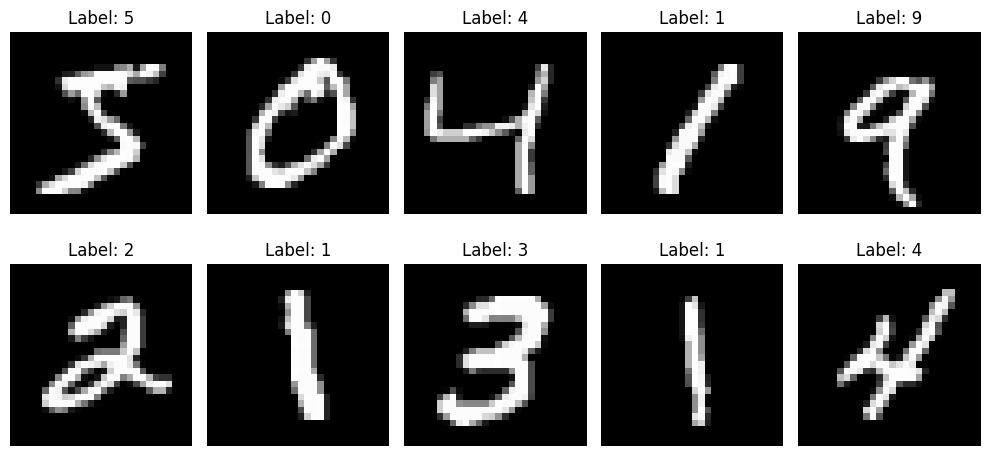

In [6]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Process the image

In [7]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


Build our CNN

In [8]:
model = keras.Sequential([

    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.BatchNormalization(),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,442 (947.04 KB)

 Trainable params: 241,994 (945.29 KB)

 Non-trainable params: 448 (1.75 KB)

compile the model

In [9]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Train It

In [10]:
history = model.fit(
    x_train,
    y_train,
    validation_split=0.1,
    epochs=30,
    batch_size=128,
    verbose=1
)

Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 32s 28ms/step - accuracy: 0.9534 - loss: 0.1526 - val_accuracy: 0.7310 - val_loss: 1.0463
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9839 - loss: 0.0552 - val_accuracy: 0.9912 - val_loss: 0.0345
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9880 - loss: 0.0386 - val_accuracy: 0.9880 - val_loss: 0.0488
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9904 - loss: 0.0327 - val_accuracy: 0.9878 - val_loss: 0.0431
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9919 - loss: 0.0261 - val_accuracy: 0.9895 - val_loss: 0.0414
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9937 - loss: 0.0201 - val_accuracy: 0.9890 - val_loss: 0.0491
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9947 - loss: 0.0173 - val_accuracy: 0.9927 - val_loss: 0.0323
Epoch 8/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9944 - loss: 0.0168 - val_accuracy: 

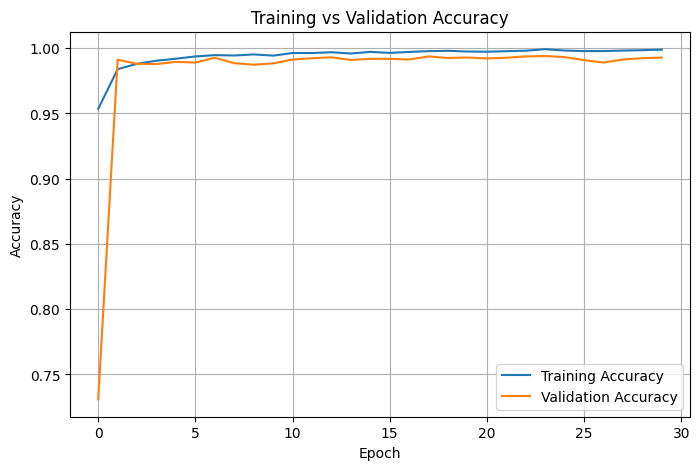

In [11]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

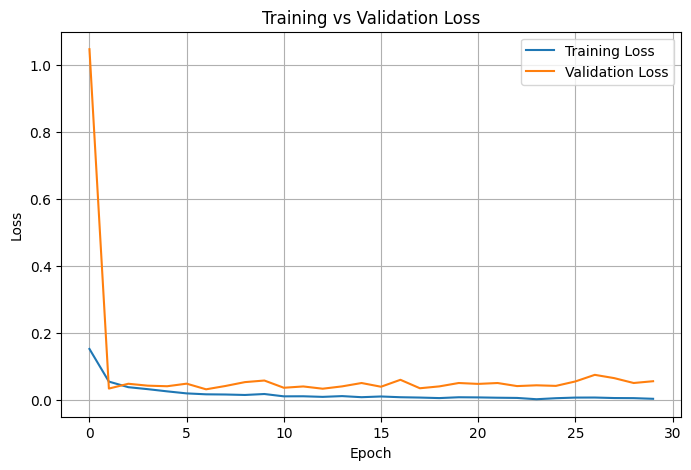

In [12]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid()
plt.show()

In [13]:
print("Final Training Accuracy:",
      history.history["accuracy"][-1])

print("Final Validation Accuracy:",
      history.history["val_accuracy"][-1])

Final Training Accuracy: 0.9988889098167419
Final Validation Accuracy: 0.9928333163261414


test on the completely unseen test set

In [14]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9930 - loss: 0.0478
Test Loss: 0.0478
Test Accuracy: 99.3000%


 Classification report

In [15]:
y_pred = model.predict(x_test, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(
    y_test,
    y_pred_classes,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9939    0.9949    0.9944       980
           1     0.9939    0.9991    0.9965      1135
           2     0.9828    0.9990    0.9909      1032
           3     0.9970    0.9921    0.9945      1010
           4     0.9939    0.9969    0.9954       982
           5     0.9944    0.9922    0.9933       892
           6     0.9968    0.9885    0.9927       958
           7     0.9961    0.9815    0.9887      1028
           8     0.9959    0.9949    0.9954       974
           9     0.9862    0.9901    0.9881      1009

    accuracy                         0.9930     10000
   macro avg     0.9931    0.9929    0.9930     10000
weighted avg     0.9930    0.9930    0.9930     10000



Confusion matrix

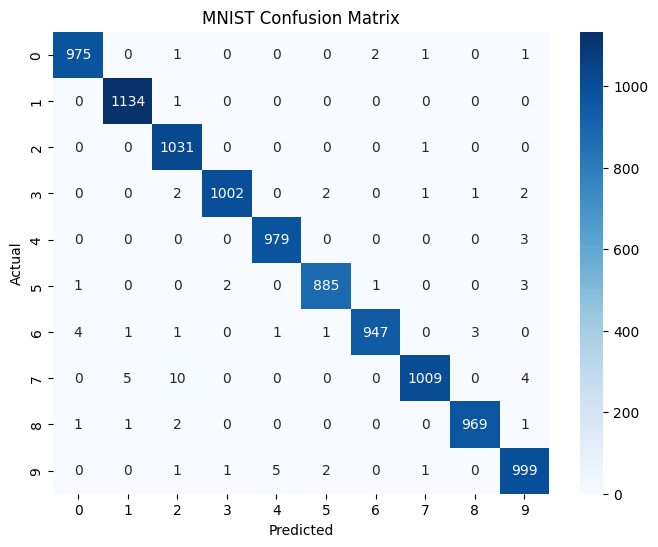

In [16]:
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MNIST Confusion Matrix")
plt.show()

 Save your trained model

In [17]:
import os

os.makedirs("models", exist_ok=True)

model.save("models/digit_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [18]:
print(os.path.exists("models/digit_model.keras"))

True


Test loading the saved model

In [19]:
loaded_model = keras.models.load_model("models/digit_model.keras")

print("Model loaded successfully!")

Model loaded successfully!


In [20]:
test_loss, test_accuracy = loaded_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Loaded Model Test Accuracy: {test_accuracy:.4%}")

Loaded Model Test Accuracy: 99.3000%


Install OpenCV

In [21]:
!pip install -q opencv-python-headless

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Create the digit preprocessing function

In [23]:
def preprocess_digit(crop):
    # Convert to grayscale
    if len(crop.shape) == 3:
        crop = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)

    # Make digit white and background black
    if np.mean(crop) > 127:
        crop = 255 - crop

    # Threshold
    _, crop = cv2.threshold(
        crop,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Find digit pixels
    coords = cv2.findNonZero(crop)

    if coords is None:
        return None

    # Bounding box
    x, y, w, h = cv2.boundingRect(coords)

    crop = crop[y:y+h, x:x+w]

    # Make a square canvas
    size = max(w, h)
    square = np.zeros((size, size), dtype=np.uint8)

    x_offset = (size - w) // 2
    y_offset = (size - h) // 2

    square[
        y_offset:y_offset+h,
        x_offset:x_offset+w
    ] = crop

    # Resize to 20x20
    square = cv2.resize(
        square,
        (20, 20),
        interpolation=cv2.INTER_AREA
    )

    # Put inside 28x28 MNIST canvas
    final = np.zeros((28, 28), dtype=np.uint8)

    final[4:24, 4:24] = square

    # Normalize
    final = final.astype("float32") / 255.0

    # Add channel
    final = np.expand_dims(final, axis=-1)

    return final

Create multi-digit segmentation

In [24]:
def segment_digits(image):

    # Convert to grayscale
    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:
        gray = image.copy()

    # Normalize canvas
    gray = cv2.normalize(
        gray,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    # Make white digit on black background
    if np.mean(gray) > 127:
        gray = 255 - gray

    # Threshold
    _, binary = cv2.threshold(
        gray,
        30,
        255,
        cv2.THRESH_BINARY
    )

    # Remove tiny noise
    kernel = np.ones((3, 3), np.uint8)

    binary = cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel
    )

    # Find contours
    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    regions = []

    for contour in contours:

        x, y, w, h = cv2.boundingRect(contour)

        # Ignore tiny noise
        if w < 5 or h < 10:
            continue

        area = w * h

        if area < 50:
            continue

        regions.append((x, y, w, h))

    # Left → right
    regions.sort(key=lambda r: r[0])

    return regions

Create the actual prediction function

In [25]:
def predict_digits(image):

    if image is None:
        return "No image."

    regions = segment_digits(image)

    print("Detected regions:", regions)

    if len(regions) == 0:
        return "No digit detected."

    predictions = []

    for x, y, w, h in regions:

        # Add small padding around digit
        padding = 5

        x1 = max(0, x - padding)
        y1 = max(0, y - padding)
        x2 = min(image.shape[1], x + w + padding)
        y2 = min(image.shape[0], y + h + padding)

        crop = image[y1:y2, x1:x2]

        processed = preprocess_digit(crop)

        if processed is None:
            continue

        # Batch dimension
        processed = np.expand_dims(
            processed,
            axis=0
        )

        # Prediction
        probabilities = loaded_model.predict(
            processed,
            verbose=0
        )[0]

        digit = np.argmax(probabilities)

        confidence = np.max(probabilities)

        print(
            f"Digit: {digit}, "
            f"Confidence: {confidence:.2%}"
        )

        predictions.append(str(digit))

    if len(predictions) == 0:
        return "No digit detected."

    return "".join(predictions)

 Test with an MNIST image first

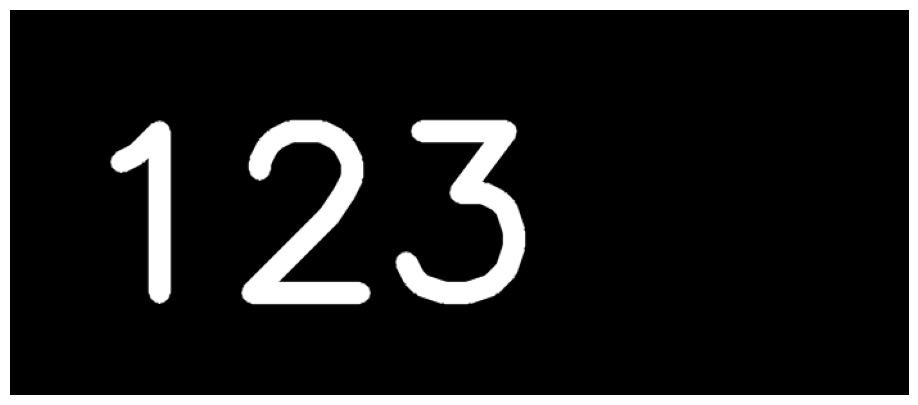

Detected regions: [(78, 86, 48, 143), (180, 85, 101, 145), (300, 85, 102, 145)]
Digit: 1, Confidence: 100.00%
Digit: 2, Confidence: 100.00%
Digit: 3, Confidence: 100.00%
Prediction: 123


In [26]:
test = np.zeros((300, 700), dtype=np.uint8)

font = cv2.FONT_HERSHEY_SIMPLEX

cv2.putText(test, "123",
            (50, 220),
            font,
            6,
            255,
            15,
            cv2.LINE_AA)

plt.figure(figsize=(12, 5))
plt.imshow(test, cmap="gray")
plt.axis("off")
plt.show()

print("Prediction:", predict_digits(test))

In [27]:
index = 0

sample = x_test[index]

prediction = predict_digits(
    (sample[:, :, 0] * 255).astype(np.uint8)
)

print("Actual digit:", y_test[index])
print("Predicted:", prediction)

Detected regions: []
Actual digit: 7
Predicted: No digit detected.


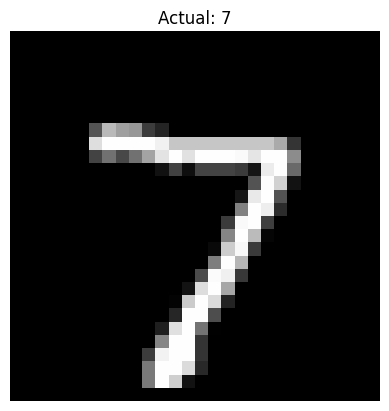

In [28]:
plt.imshow(x_test[index].squeeze(), cmap="gray")
plt.title(f"Actual: {y_test[index]}")
plt.axis("off")
plt.show()

Create a test image containing 123

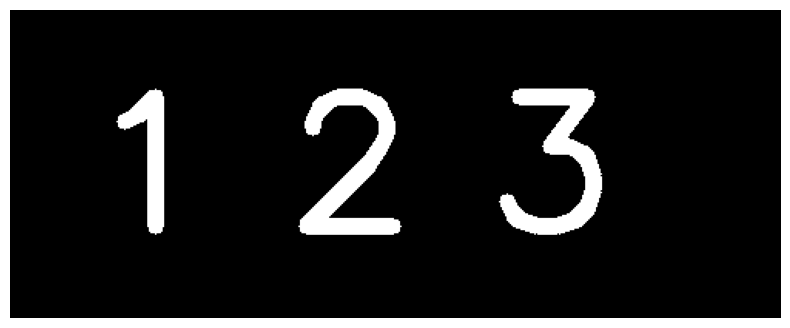

In [29]:
# Create a blank canvas
canvas = np.zeros((200, 500), dtype=np.uint8)

# Draw three digits
font = cv2.FONT_HERSHEY_SIMPLEX

cv2.putText(canvas, "1", (50, 140), font, 4, 255, 10)
cv2.putText(canvas, "2", (180, 140), font, 4, 255, 10)
cv2.putText(canvas, "3", (310, 140), font, 4, 255, 10)

# Display
plt.figure(figsize=(10, 4))
plt.imshow(canvas, cmap="gray")
plt.axis("off")
plt.show()

Run our multi-digit prediction

In [30]:
prediction = predict_digits(canvas)

print("Predicted number:", prediction)

Detected regions: [(70, 52, 30, 93), (188, 51, 65, 95), (318, 51, 66, 95)]
Digit: 1, Confidence: 100.00%
Digit: 2, Confidence: 100.00%
Digit: 3, Confidence: 100.00%
Predicted number: 123


Visualize what the segmentation detected

In [31]:
regions = segment_digits(canvas)

print("Number of detected regions:", len(regions))
print("Regions:", regions)

Number of detected regions: 3
Regions: [(70, 52, 30, 93), (188, 51, 65, 95), (318, 51, 66, 95)]


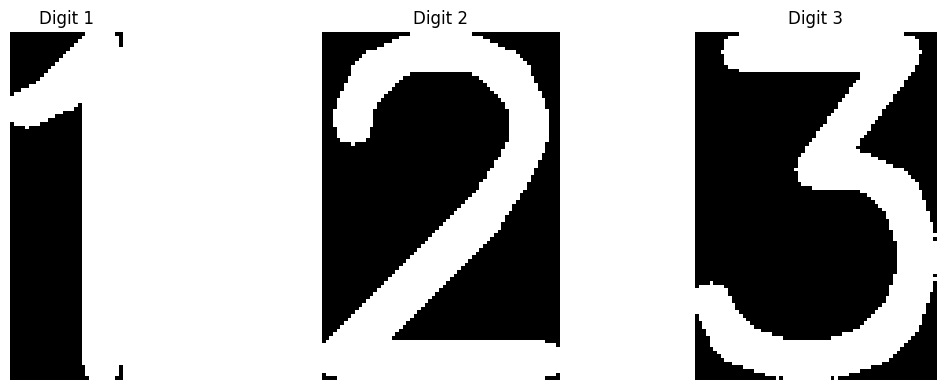

In [32]:
plt.figure(figsize=(12, 4))

for i, (x, y, w, h) in enumerate(regions):

    crop = canvas[y:y+h, x:x+w]

    plt.subplot(1, len(regions), i + 1)
    plt.imshow(crop, cmap="gray")
    plt.title(f"Digit {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

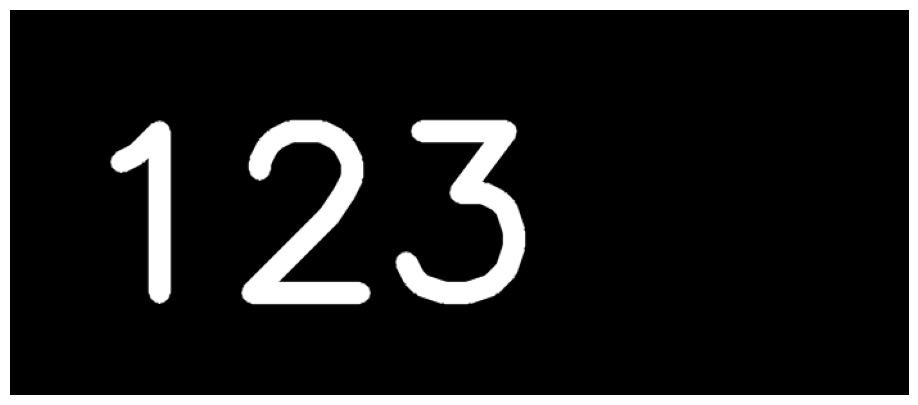

Detected regions: [(78, 86, 48, 143), (180, 85, 101, 145), (300, 85, 102, 145)]
Digit: 1, Confidence: 100.00%
Digit: 2, Confidence: 100.00%
Digit: 3, Confidence: 100.00%
Prediction: 123


In [33]:
test = np.zeros((300, 700), dtype=np.uint8)

font = cv2.FONT_HERSHEY_SIMPLEX

cv2.putText(test, "123",
            (50, 220),
            font,
            6,
            255,
            15,
            cv2.LINE_AA)

plt.figure(figsize=(12, 5))
plt.imshow(test, cmap="gray")
plt.axis("off")
plt.show()

print("Prediction:", predict_digits(test))

Create the Gradio app

In [34]:
def recognize_from_canvas(value):

    if value is None:
        return "Please draw a digit."

    # Sketchpad/ImageEditor returns a dictionary
    if isinstance(value, dict):
        image = value.get("composite")

        # If composite isn't available, try the drawing layer
        if image is None:
            layers = value.get("layers", [])
            if layers:
                image = layers[-1]

    else:
        image = value

    if image is None:
        return "Please draw a digit."

    image = np.array(image)

    print("Received image shape:", image.shape)

    # Convert to grayscale
    if image.ndim == 3:

        if image.shape[2] == 4:
            gray = cv2.cvtColor(
                image,
                cv2.COLOR_RGBA2GRAY
            )
        else:
            gray = cv2.cvtColor(
                image,
                cv2.COLOR_RGB2GRAY
            )

    else:
        gray = image

    # Blank canvas
    if np.max(gray) < 10:
        return "Please draw a digit."

    prediction = predict_digits(gray)

    return prediction

In [40]:
import gradio as gr

with gr.Blocks(
    title="Handwritten Digit Recognition"
) as demo:

    gr.Markdown(
        """
        # ✍️ Handwritten Digit Recognition

        Draw one or multiple digits.

        **Examples:** `7` → `7` &nbsp;&nbsp; `12` → `12` &nbsp;&nbsp; `123` → `123`
        """
    )

    canvas = gr.Sketchpad(
        label="Draw your digit(s)",
        type="numpy",
        canvas_size=(700, 350),
        height=350,
        width=700
    )

    with gr.Row():
        predict_button = gr.Button("🔍 Predict")
        clear_button = gr.ClearButton(canvas)

    result = gr.Textbox(
        label="Prediction"
    )

    predict_button.click(
        fn=recognize_from_canvas,
        inputs=canvas,
        outputs=result
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d620ad71fd61a3c2cb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Build the interface

In [38]:
def segment_digits(image):

    # Convert to grayscale
    if len(image.shape) == 3:
        if image.shape[2] == 4:
            gray = cv2.cvtColor(image, cv2.COLOR_RGBA2GRAY)
        else:
            gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:
        gray = image.copy()

    # Normalize brightness
    gray = cv2.normalize(
        gray,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    # Convert dark writing on white paper
    # into white writing on black background
    if np.mean(gray) > 127:
        gray = 255 - gray

    # Threshold
    _, binary = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Connect small gaps inside handwritten digits
    kernel = np.ones((3, 3), np.uint8)

    binary = cv2.morphologyEx(
        binary,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=1
    )

    # Slight dilation helps connect broken strokes
    binary = cv2.dilate(
        binary,
        kernel,
        iterations=1
    )

    # Find contours
    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    regions = []

    for contour in contours:

        x, y, w, h = cv2.boundingRect(contour)

        # Ignore very small noise
        if w < 8 or h < 12:
            continue

        area = w * h

        if area < 100:
            continue

        regions.append((x, y, w, h))

    # Sort left → right
    regions.sort(key=lambda r: r[0])

    return regions

In [41]:
import gradio as gr

with gr.Blocks(
    title="Handwritten Digit Recognition"
) as demo:

    gr.Markdown(
        """
        # ✍️ Handwritten Digit Recognition

        Recognize handwritten digits from either:

        - ✏️ Drawing on the canvas
        - 📷 Uploading a notebook/image

        **Examples:** `7` → `7` &nbsp;&nbsp; `12` → `12` &nbsp;&nbsp; `123` → `123`
        """
    )

    with gr.Tabs():

        # -----------------------------
        # DRAWING TAB
        # -----------------------------
        with gr.Tab("✏️ Draw Digits"):

            canvas = gr.Sketchpad(
                label="Draw your digit(s)",
                type="numpy",
                canvas_size=(700, 350),
                height=350,
                width=700
            )

            with gr.Row():

                predict_canvas_button = gr.Button(
                    "🔍 Predict Drawing"
                )

                clear_button = gr.ClearButton(
                    canvas
                )

            canvas_result = gr.Textbox(
                label="Prediction"
            )

            predict_canvas_button.click(
                fn=recognize_from_canvas,
                inputs=canvas,
                outputs=canvas_result
            )


        # -----------------------------
        # UPLOAD TAB
        # -----------------------------
        with gr.Tab("📷 Upload Notebook Image"):

            upload_image = gr.Image(
                label="Upload handwritten digit image",
                type="numpy"
            )

            predict_upload_button = gr.Button(
                "🔍 Predict Uploaded Image"
            )

            upload_result = gr.Textbox(
                label="Prediction"
            )

            predict_upload_button.click(
                fn=predict_digits,
                inputs=upload_image,
                outputs=upload_result
            )


demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b73a181f770e29b8f7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [42]:
def recognize_from_canvas(value):

    if value is None:
        return "Please draw a digit."

    if isinstance(value, dict):

        image = value.get("composite")

        if image is None:
            layers = value.get("layers", [])

            if layers:
                image = layers[-1]

    else:
        image = value

    if image is None:
        return "Please draw a digit."

    image = np.array(image)

    print("Received image shape:", image.shape)

    # Convert to grayscale
    if image.ndim == 3:

        if image.shape[2] == 4:
            gray = cv2.cvtColor(
                image,
                cv2.COLOR_RGBA2GRAY
            )
        else:
            gray = cv2.cvtColor(
                image,
                cv2.COLOR_RGB2GRAY
            )

    else:
        gray = image

    # Blank canvas
    if np.max(gray) < 10:
        return "Please draw a digit."

    return predict_digits(gray)

In [43]:
!pip install -q mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 13.9 MB/s eta 0:00:00


In [44]:
!wget -q https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task

In [45]:
import os

print(os.path.exists("hand_landmarker.task"))

True


In [46]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

base_options = python.BaseOptions(
    model_asset_path="hand_landmarker.task"
)

options = vision.HandLandmarkerOptions(
    base_options=base_options,
    num_hands=1
)

hand_landmarker = vision.HandLandmarker.create_from_options(options)

print("Hand detector loaded successfully!")

Hand detector loaded successfully!


In [47]:
# Air drawing canvas
air_canvas = np.zeros((350, 700), dtype=np.uint8)

prev_point = None
frame_count = 0
live_prediction = ""


def air_draw(frame):

    global air_canvas
    global prev_point
    global frame_count
    global live_prediction

    if frame is None:
        return None

    frame = np.array(frame)

    # MediaPipe image
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame
    )

    # Detect hand
    result = hand_landmarker.detect(mp_image)

    # Copy webcam frame
    output = frame.copy()

    if result.hand_landmarks:

        hand = result.hand_landmarks[0]

        # Index fingertip = landmark 8
        fingertip = hand[8]

        h, w = frame.shape[:2]

        # Finger position on webcam
        x = int(fingertip.x * w)
        y = int(fingertip.y * h)

        # Finger position on drawing canvas
        canvas_x = int(fingertip.x * 700)
        canvas_y = int(fingertip.y * 350)

        canvas_x = max(0, min(699, canvas_x))
        canvas_y = max(0, min(349, canvas_y))

        current_point = (canvas_x, canvas_y)

        # Draw line
        if prev_point is not None:

            cv2.line(
                air_canvas,
                prev_point,
                current_point,
                255,
                12,
                cv2.LINE_AA
            )

        prev_point = current_point

        # Draw fingertip marker
        cv2.circle(
            output,
            (x, y),
            12,
            (0, 255, 0),
            -1
        )

        cv2.circle(
            output,
            (x, y),
            16,
            (255, 255, 255),
            2
        )

    else:

        # Hand disappeared
        prev_point = None

    # --------------------------------
    # Put drawing ON webcam screen
    # --------------------------------

    drawing_rgb = cv2.cvtColor(
        air_canvas,
        cv2.COLOR_GRAY2RGB
    )

    drawing_rgb = cv2.resize(
        drawing_rgb,
        (output.shape[1], output.shape[0])
    )

    # Create mask for only the white drawing
    mask = drawing_rgb[:, :, 0] > 20

    # Make drawing visible on webcam
    output[mask] = [255, 255, 0]

    # --------------------------------
    # Live prediction
    # --------------------------------

    frame_count += 1

    # Predict every 10 frames
    if frame_count % 10 == 0:

        if np.max(air_canvas) > 10:

            try:
                live_prediction = predict_digits(
                    air_canvas
                )
            except:
                live_prediction = ""

    # --------------------------------
    # Show prediction on same screen
    # --------------------------------

    cv2.rectangle(
        output,
        (10, 10),
        (300, 75),
        (0, 0, 0),
        -1
    )

    cv2.putText(
        output,
        "Prediction: " + str(live_prediction),
        (20, 55),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 255),
        2
    )

    # Instruction
    cv2.putText(
        output,
        "Move index finger to draw",
        (20, output.shape[0] - 20),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

    return output

In [48]:
def clear_air_drawing():

    global air_canvas
    global prev_point
    global live_prediction

    air_canvas = np.zeros(
        (350, 700),
        dtype=np.uint8
    )

    prev_point = None
    live_prediction = ""

    return None

In [49]:
def predict_air_drawing():

    if np.max(air_canvas) < 10:
        return "Please draw a digit first."

    return predict_digits(air_canvas)

In [50]:
import gradio as gr

with gr.Blocks(
    title="Handwritten Digit Recognition"
) as demo:

    gr.Markdown(
        """
        # ✍️ Handwritten Digit Recognition

        ### 🎥 Air Drawing

        Move your **index finger** in front of the webcam.
        The trace and prediction appear directly on the live screen.
        """
    )

    webcam = gr.Image(
        label="🎥 Air Drawing Camera",
        sources=["webcam"],
        type="numpy"
    )

    with gr.Row():

        clear_button = gr.Button(
            "🗑️ Clear Drawing"
        )

    webcam.stream(
        fn=air_draw,
        inputs=webcam,
        outputs=webcam,
        stream_every=0.1
    )

    clear_button.click(
        fn=clear_air_drawing,
        inputs=None,
        outputs=webcam
    )


demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c14028c64f51e0f572.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
